<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №8
## по курсу «Технологии машинного обучения»

### Тема: Методы обучения без учителя

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

## 1. Описание задания

**Цель работы:** изучение методов кластеризации и снижения размерности.

**Задание:**
1. Выбрать набор данных для решения задачи обучения без учителя.
2. Выбрать подмножество признаков (более двух), не обязательно включая целевой признак. Полученный датасет — D1.
3. Методом главных компонент (PCA) снизить размерность D1 до двух. Полученный датасет — D2.
4. Алгоритмом t-SNE снизить размерность D1 до двух. Полученный датасет — D3.
5. Визуализировать точки D2 и D3. Определить, в каком случае кластеры выделены наиболее явно.
6. Для D1, D2 и D3 провести кластеризацию не менее чем тремя методами и оценить качество метриками.
7. Сделать выводы о том, какой метод кластеризации и почему оказался лучше для каждого из датасетов.

Ссылка на постановку задания: https://github.com/ugapanyuk/courses_current/wiki/LAB_TMO_CLUSTER

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import warnings

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score

matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore", category=RuntimeWarning)  # лишние предупреждения numpy на macOS

BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"

## 2. Набор данных

Используется тот же финансовый датасет, что и в ЛР2–ЛР6, — **Loan Prediction Problem Dataset** (заявки на кредит, https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset). Для обучения без учителя целевой признак `Loan_Status` не используется при построении кластеров: он понадобится только для сравнения результатов в конце.

In [2]:
df = pd.read_csv("loan_prediction.csv")
print("Размер:", df.shape)
df.head()

Размер: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 3. Предобработка и выбор признаков (датасет D1)

Пропуски заполняем медианой и модой, категориальные признаки кодируем (так же, как в предыдущих работах). Для кластеризации выбираем **шесть признаков** — доходы заявителя и созаёмщика, сумму и срок кредита, кредитную историю и число иждивенцев. Целевой признак в подмножество не входит.

Доходы и сумма кредита сильно скошены (у немногих заявителей очень большие значения), поэтому берём их логарифм, а затем масштабируем все признаки (StandardScaler): расстояния в кластеризации чувствительны к масштабу.

In [3]:
data = df.drop(columns=["Loan_ID"])

data[["LoanAmount"]] = SimpleImputer(strategy="median").fit_transform(data[["LoanAmount"]])
mode_cols = ["Gender", "Married", "Dependents", "Self_Employed", "Loan_Amount_Term", "Credit_History"]
data[mode_cols] = SimpleImputer(strategy="most_frequent").fit_transform(data[mode_cols])
data["Dependents"] = OrdinalEncoder(categories=[["0", "1", "2", "3+"]]).fit_transform(data[["Dependents"]])
data["Loan_Status"] = LabelEncoder().fit_transform(data["Loan_Status"])
print("Пропусков в выбранных признаках:",
      data[["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History", "Dependents"]].isnull().sum().sum())

Пропусков в выбранных признаках: 0


In [4]:
features = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History", "Dependents"]
D1_raw = data[features].astype(float).copy()
for col in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]:
    D1_raw[col] = np.log1p(D1_raw[col])      # логарифм скошенных признаков

D1 = StandardScaler().fit_transform(D1_raw)  # датасет D1: 614 объектов, 6 признаков
y_true = data["Loan_Status"].values          # используется только для сравнения в конце
credit = data["Credit_History"].values       # для раскраски графиков
print("D1:", D1.shape)

D1: (614, 6)


## 4. Снижение размерности

### 4.1. Метод главных компонент (датасет D2)

In [5]:
pca = PCA(n_components=2, random_state=1)
D2 = pca.fit_transform(D1)
print("D2:", D2.shape)
print("Доля дисперсии по компонентам:", pca.explained_variance_ratio_.round(3))
print("Всего объяснено:", pca.explained_variance_ratio_.sum().round(3))

D2: (614, 2)
Доля дисперсии по компонентам: [0.268 0.194]
Всего объяснено: 0.462


### 4.2. Алгоритм t-SNE (датасет D3)

In [6]:
tsne = TSNE(n_components=2, perplexity=30, random_state=1, init="pca")
D3 = tsne.fit_transform(D1)
print("D3:", D3.shape)

D3: (614, 2)


## 5. Визуализация D2 и D3

Раскрасим точки по кредитной истории (признак из D1): она делит заявителей на две явные группы, и по ней видно, насколько хорошо метод снижения размерности сохранил структуру данных.

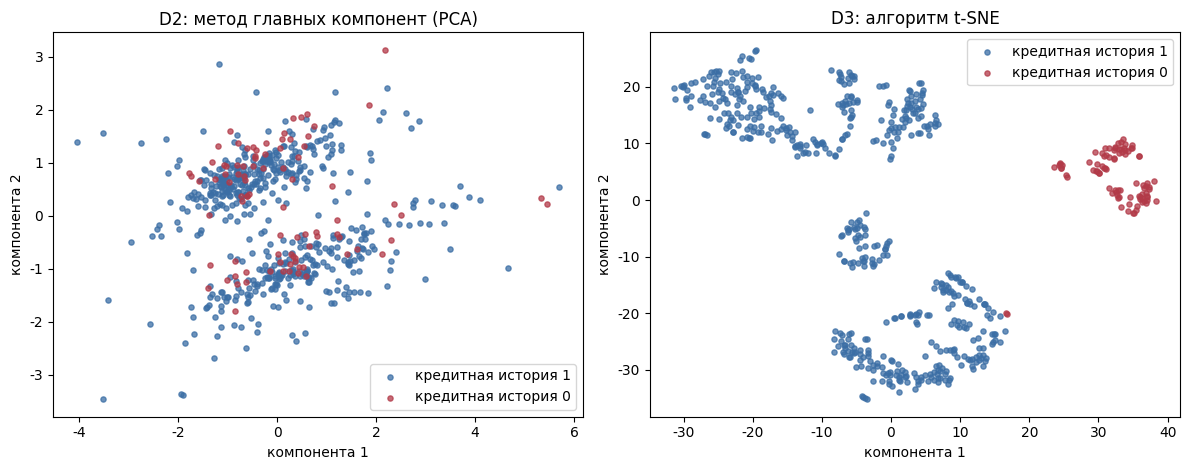

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (title, D) in zip(axes, [("D2: метод главных компонент (PCA)", D2), ("D3: алгоритм t-SNE", D3)]):
    ax.scatter(D[credit == 1, 0], D[credit == 1, 1], s=14, color=BLUE, alpha=0.75, label="кредитная история 1")
    ax.scatter(D[credit == 0, 0], D[credit == 0, 1], s=14, color=RED, alpha=0.75, label="кредитная история 0")
    ax.set_title(title)
    ax.set_xlabel("компонента 1")
    ax.set_ylabel("компонента 2")
    ax.legend()
plt.tight_layout()
plt.show()

**Пояснение к графикам.** Точки — заявки на кредит, цвет показывает кредитную историю (1 — хорошая, 0 — плохая). Слева — проекция методом PCA: две компоненты объясняют только 46,2 % разброса данных, поэтому часть информации потеряна. Точки сливаются в одно облако с двумя уплотнениями (сверху и снизу), заявки с плохой кредитной историей (красные) лежат среди остальных, чётких границ нет. Справа — t-SNE: заявки образуют несколько отдельных «островов», причём красные точки собраны в компактную группу справа. То есть t-SNE выделяет кластеры гораздо явнее, чем PCA. Расстояния между островами и сами оси t-SNE не имеют строгого смысла, важно лишь, какие точки оказались рядом.

**Простыми словами:** у каждой заявки шесть признаков (доход, сумма кредита, срок и т. д.), а нарисовать шестимерную картинку нельзя. PCA и t-SNE — два способа «сплющить» данные до плоского рисунка, где похожие заявки лежат рядом. График нужен, чтобы глазами проверить, есть ли в данных естественные группы и какой способ показывает их лучше.

## 6. Кластеризация датасетов D1, D2 и D3

Используем три метода из лекции: **K-средних (KMeans)**, **иерархическую (агломеративную) кластеризацию** со связью Уорда и **DBSCAN** (плотностной метод, сам определяет число кластеров и выделяет шум).

Качество оцениваем тремя внутренними метриками (разметка не нужна):
- **коэффициент силуэта** (silhouette) — от −1 до 1, чем больше, тем лучше;
- **индекс Калинского–Харабаса** — чем больше, тем лучше;
- **индекс Дэвиса–Болдина** — чем меньше, тем лучше.

### 6.1. Выбор числа кластеров для K-средних

Число кластеров смотрим по двум графикам на D1 (от 2 до 8): по инерции (сумма квадратов расстояний до центров, «метод локтя») и по коэффициенту силуэта.

k = 2: инерция 2988, силуэт 0.2405
k = 3: инерция 2475, силуэт 0.2820
k = 4: инерция 2080, силуэт 0.3050
k = 5: инерция 1760, силуэт 0.3031
k = 6: инерция 1531, силуэт 0.3206
k = 7: инерция 1433, силуэт 0.3325
k = 8: инерция 1337, силуэт 0.3418


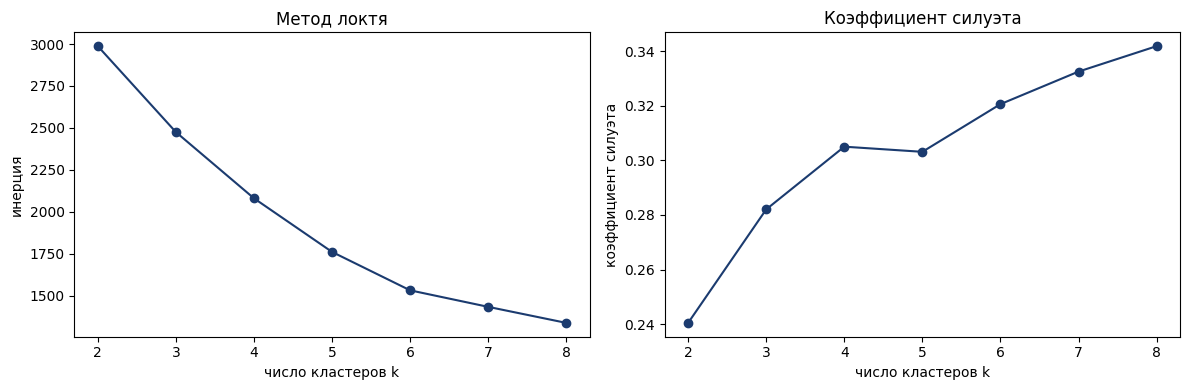

In [8]:
ks = list(range(2, 9))
sil, inertia = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=1).fit(D1)
    sil.append(silhouette_score(D1, km_k.labels_))
    inertia.append(km_k.inertia_)
for k, s, i in zip(ks, sil, inertia):
    print(f"k = {k}: инерция {i:.0f}, силуэт {s:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertia, marker="o", color=BLUE_DARK)
axes[0].set_xlabel("число кластеров k")
axes[0].set_ylabel("инерция")
axes[0].set_title("Метод локтя")
axes[1].plot(ks, sil, marker="o", color=BLUE_DARK)
axes[1].set_xlabel("число кластеров k")
axes[1].set_ylabel("коэффициент силуэта")
axes[1].set_title("Коэффициент силуэта")
plt.tight_layout()
plt.show()

**Пояснение к графикам.** Слева — метод локтя: по оси X число кластеров k, по оси Y инерция (сумма квадратов расстояний до центров кластеров). Инерция падает плавно с 2988 при k = 2 до 1337 при k = 8, резкого изгиба («локтя») нет, поэтому по этому графику число кластеров однозначно не определить. Справа — коэффициент силуэта (чем больше, тем лучше разделены кластеры): он растёт с 0,241 при k = 2 до 0,305 при k = 4, а дальше увеличивается медленно (0,342 при k = 8), хотя кластеры при этом дробятся на всё более мелкие. Поэтому берём **k = 4** — компромисс между качеством и понятностью кластеров.

**Простыми словами:** алгоритм сам делит заявки на группы, но число групп нужно задать заранее. Эти два графика помогают его выбрать: «локоть» показывает, после какого числа групп дальнейшее деление почти ничего не улучшает, а силуэт — насколько чётко группы отделены друг от друга. Они нужны, чтобы выбор k = 4 был обоснованным, а не случайным.

In [9]:
best_k = 4
print("Выбрано число кластеров:", best_k)

Выбрано число кластеров: 4


### 6.2. Подбор параметров DBSCAN

У DBSCAN два параметра: радиус окрестности `eps` и минимальное число соседей. Перебираем `eps` и выбираем значение с наибольшим силуэтом, но только среди тех, где в шум попадает не более 25 % точек (иначе метод «выбрасывает» почти всё и метрика получается завышенной). Шумовые точки при подсчёте силуэта не учитываются.

In [10]:
def dbscan_best(D, eps_grid, min_samples):
    best = None
    for eps in eps_grid:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(D)
        mask = labels != -1
        n_cl = len(set(labels[mask]))
        if n_cl < 2 or n_cl > 10 or (~mask).mean() > 0.25:
            continue
        s = silhouette_score(D[mask], labels[mask])
        if best is None or s > best[0]:
            best = (s, eps, labels)
    return best

params = {}
for name, D, grid in [("D1", D1, np.arange(0.5, 4.01, 0.1)),
                      ("D2", D2, np.arange(0.1, 2.51, 0.05)),
                      ("D3", D3, np.arange(1.0, 8.01, 0.25))]:
    s, eps, labels = dbscan_best(D, grid, min_samples=10)
    params[name] = (eps, labels)
    print(f"{name}: eps = {eps:.2f}, кластеров {len(set(labels)) - (1 if -1 in labels else 0)}, шум {np.sum(labels == -1)} точек, силуэт {s:.4f}")

D1: eps = 1.00, кластеров 3, шум 153 точек, силуэт 0.3376


D2: eps = 0.35, кластеров 2, шум 88 точек, силуэт 0.5227
D3: eps = 3.25, кластеров 5, шум 11 точек, силуэт 0.5428


### 6.3. Кластеризация тремя методами и метрики

In [11]:
datasets = {"D1": D1, "D2": D2, "D3": D3}
all_labels = {}
rows = []
for dname, D in datasets.items():
    km = KMeans(n_clusters=best_k, n_init=10, random_state=1).fit_predict(D)
    ag = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(D)
    db = params[dname][1]
    for mname, labels in [("KMeans", km), ("Иерархическая", ag), ("DBSCAN", db)]:
        all_labels[(dname, mname)] = labels
        mask = labels != -1
        n_cl = len(set(labels[mask]))
        rows.append({
            "Датасет": dname, "Метод": mname, "Кластеров": n_cl, "Шум": int((~mask).sum()),
            "Силуэт": silhouette_score(D[mask], labels[mask]),
            "Калинский–Харабас": calinski_harabasz_score(D[mask], labels[mask]),
            "Дэвис–Болдин": davies_bouldin_score(D[mask], labels[mask]),
        })
metrics = pd.DataFrame(rows).set_index(["Датасет", "Метод"])
metrics.round(3)

Кластеров  Шум  Силуэт  Калинский–Харабас  Дэвис–Болдин
Датасет Метод                                                                 
D1      KMeans                 4    0   0.305            156.799         1.295
        Иерархическая          4    0   0.252            128.963         1.401
        DBSCAN                 3  153   0.338             64.926         0.760
D2      KMeans                 4    0   0.441            504.860         0.751
        Иерархическая          4    0   0.406            462.748         0.776
        DBSCAN                 2   88   0.523            610.775         0.796
D3      KMeans                 4    0   0.600           1620.168         0.564
        Иерархическая          4    0   0.595           1546.025         0.540
        DBSCAN                 5   11   0.543           1584.982         0.524

### 6.4. Результаты кластеризации на плоскостях D2 и D3

Раскрасим точки по найденным кластерам. Серые крестики у DBSCAN — шум.

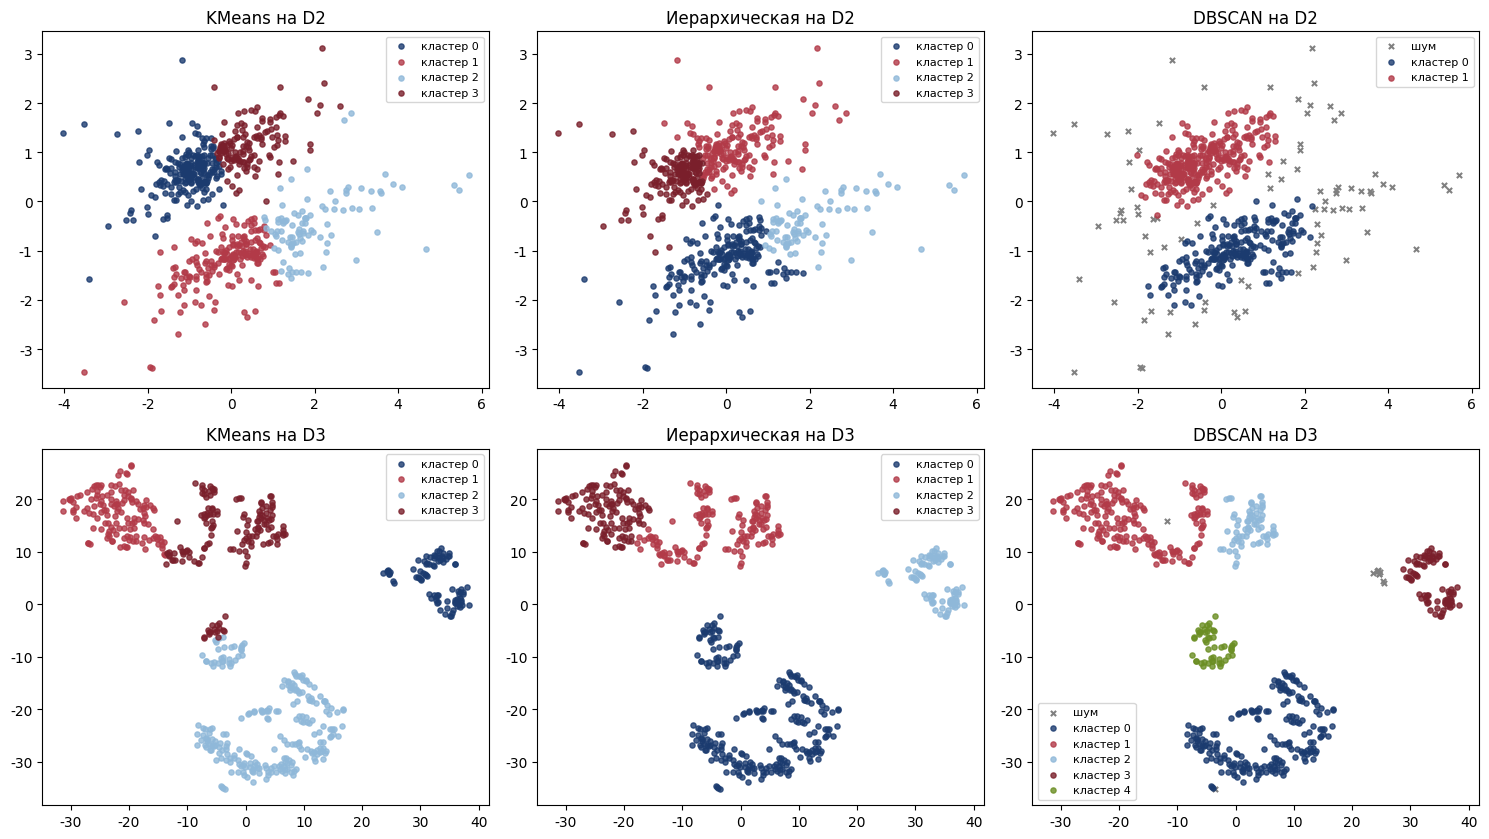

In [12]:
colors = [BLUE_DARK, RED, BLUE_LIGHT, RED_DARK, "#6B8E23", "#DAA520", "#708090", "#8B4513"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for i, (dname, D) in enumerate([("D2", D2), ("D3", D3)]):
    for j, mname in enumerate(["KMeans", "Иерархическая", "DBSCAN"]):
        labels = all_labels[(dname, mname)]
        ax = axes[i, j]
        for lab in sorted(set(labels)):
            m = labels == lab
            if lab == -1:
                ax.scatter(D[m, 0], D[m, 1], s=14, color="grey", marker="x", label="шум")
            else:
                ax.scatter(D[m, 0], D[m, 1], s=14, color=colors[lab % len(colors)], alpha=0.8, label=f"кластер {lab}")
        ax.set_title(f"{mname} на {dname}")
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Пояснение к графикам.** Каждая точка раскрашена по найденному кластеру, серые крестики — шум (точки, которые DBSCAN не отнёс ни к одному кластеру). Верхний ряд — плоскость PCA (D2). KMeans и иерархическая кластеризация делят одно сплошное облако на четыре части с ровными границами, кластеры соприкасаются, зазоров между ними нет. DBSCAN находит два плотных ядра (верхнее и нижнее), а редкие точки по краям отмечает как шум — их 88. Нижний ряд — плоскость t-SNE (D3). Здесь кластеры лучше согласуются с видимыми «островами»: DBSCAN выделяет пять групп практически по островам и отбрасывает только 11 точек (маленькая группа у правого края). KMeans и иерархический метод задают ровно четыре кластера, поэтому могут объединять близкие острова или разрезать один остров на части. Метрики подтверждают картинку: на D3 силуэт KMeans 0,600, на D2 — 0,441, на D1 — 0,305, то есть лучше всего кластеры разделяются на t-SNE.

**Простыми словами:** это те же картинки, что и раньше, но точки покрашены в цвета групп, которые нашёл алгоритм. По ним видно, как каждый метод «разрезал» данные: аккуратно по естественным островам или произвольно. График нужен, чтобы наглядно сравнить три метода и подтвердить выводы, сделанные по метрикам.

## 7. Сравнение с исходной разметкой

Целевой признак `Loan_Status` в кластеризации не участвовал. Скорректированный индекс Рэнда (ARI) показывает, насколько найденные кластеры совпадают с ним (0 — случайно, 1 — полностью совпадают). Это внешняя метрика, и для задачи обучения без учителя она нужна только как справочная.

In [13]:
ari = {}
for (dname, mname), labels in all_labels.items():
    ari[(dname, mname)] = adjusted_rand_score(y_true, labels)
ari_df = pd.Series(ari, name="ARI с Loan_Status").to_frame()
ari_df.index.names = ["Датасет", "Метод"]
ari_df.round(3)

ARI с Loan_Status
Датасет Метод                           
D1      KMeans                     0.146
        Иерархическая              0.172
        DBSCAN                     0.198
D2      KMeans                     0.009
        Иерархическая             -0.000
        DBSCAN                     0.014
D3      KMeans                     0.111
        Иерархическая              0.110
        DBSCAN                     0.102

## 8. Выводы

1. Для обучения без учителя использован датасет Loan Prediction. Датасет D1 составили шесть признаков без целевого (доходы заявителя и созаёмщика, сумма и срок кредита, кредитная история, число иждивенцев); доходы и сумма кредита прологарифмированы, все признаки масштабированы. Метод главных компонент (D2) сохранил 46 % дисперсии (27 % и 19 % по двум компонентам), t-SNE (D3) отдельной доли дисперсии не даёт.
2. На графиках кластеры **наиболее явно выделены на D3 (t-SNE)**: видны отдельные «острова» точек, а заявители с плохой кредитной историей образуют обособленную группу справа. На D2 (PCA) видны только две размытые полосы, точки разных групп перекрываются. Причина: PCA сохраняет глобальную линейную структуру и «сжимает» шесть признаков в плоскость, а t-SNE сохраняет близость соседей и поэтому лучше разделяет локальные группы.
3. **Датасет D1 (6 признаков).** Лучшим по всем точкам оказался **K-средних**: силуэт 0,305, индекс Калинского–Харабаса 156,8 — выше, чем у иерархической кластеризации (0,252 и 129,0). У DBSCAN силуэт выше (0,338), но он отнёс в шум 153 точки из 614 (25 %) и нашёл всего три кластера, поэтому для D1 его результат нельзя считать лучшим.
4. **Датасет D2 (PCA).** Лучший по сплошному разбиению — **K-средних** (силуэт 0,441, индекс Дэвиса–Болдина 0,751 — лучший среди методов; иерархическая: 0,406 и 0,776). DBSCAN даёт максимальный силуэт (0,523) и индекс Калинского–Харабаса (610,8), но только за счёт двух крупных кластеров и 88 точек шума (14 %).
5. **Датасет D3 (t-SNE).** Метрики здесь самые высокие: **K-средних** и **иерархическая кластеризация** дают почти одинаковый результат (силуэт 0,600 и 0,595; индекс Дэвиса–Болдина 0,564 и 0,540), то есть для D3 оба метода одинаково хороши. DBSCAN нашёл пять кластеров, совпадающих с видимыми «островами», с небольшим шумом (11 точек), но с чуть меньшим силуэтом (0,543).
6. Метрики на D1, D2 и D3 строго сравнивать нельзя: они посчитаны в пространствах разной размерности, а расстояния в t-SNE искажены. Поэтому выбор метода сделан отдельно для каждого датасета.
7. Скорректированный индекс Рэнда с целевым признаком Loan_Status очень низкий (от 0 до 0,20; лучший — у DBSCAN на D1, 0,198). Это нормально: кластеры объединяют заявителей по доходам, суммам и числу иждивенцев, а не по решению банка.
8. Общий вывод: на этом датасете самым устойчивым методом является K-средних (хорошее качество на всех трёх датасетах и разбиение всех точек); иерархическая кластеризация почти не уступает ему на D2 и D3; DBSCAN полезен как способ выделить шумовые точки, но сильно зависит от параметров и на D1 и D2 отбрасывает заметную долю данных.
